<a href="https://colab.research.google.com/github/CooL-Legend/CSCI544-DLM/blob/adi-e2/notebooks/gsm8k/Experiment_2_Dev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

# Experiment 2: Two-Step Lookahead MEDAL vs. AB-MEDAL on GSM8K — Dev (5 Questions)

This notebook evaluates **Experiment 2 (E2)** comparing **MEDAL** and **AB-MEDAL** on GSM8K using a **Two-Step Lookahead Fractional Information Gain (FIG)** reward function with `LLaDA-8B-Instruct`.

### Mathematical Formulation:
Rather than computing immediate 1-step information gain, for each candidate child state $s_i$, search projects the highest-confidence action $a^*_i \in A(s_i)$ to form grandchild $g_i = s_i \oplus a^*_i$, computing:
$$
R_{\mathrm{FIG}}(s, s_i) = \frac{H(s) - H(g_i)}{\max(H(s), \epsilon)}
$$

- **MEDAL (Two-Step Ahead)**: Expands all $K_2$ child actions at once; for each child $s_i$, evaluates $s_i$ and its greedy grandchild $g_i$, caching both states and computing $R_{\mathrm{FIG}}(s, s_i)$. Backpropagates mean backed-up rewards.
- **AB-MEDAL (Two-Step Ahead)**: When selecting `GEN`, expands the top remaining action from $s \to s_i$, then greedily takes the top action from $s_i \to g_i$, evaluates both forwards, updates Student-$t$ Gaussian posteriors with $R_{\mathrm{FIG}}$, and backpropagates.
- **State Evaluation Caching**: Grandchild analyses are cached in `cached_analyses` so that subsequent tree expansions incur **0 redundant NFEs**.


## 1. Verify GPU Hardware
Verify that a CUDA GPU supporting bfloat16 (recommended: L4 or A100 with $\ge 22$ GiB VRAM) is active.

In [1]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError('Select a CUDA GPU runtime in Colab (L4 or A100), then reconnect.')
gpu = torch.cuda.get_device_properties(0)
vram_gb = gpu.total_memory / (1024 ** 3)
print(f'GPU: {gpu.name} | Compute Capability: {gpu.major}.{gpu.minor} | Total VRAM: {vram_gb:.2f} GiB')
if vram_gb < 20.0:
    print('Warning: VRAM is below 22 GiB. If OOM occurs, use --batch-size 1.')
else:
    print('VRAM check passed.')


GPU: NVIDIA L4 | Compute Capability: 8.9 | Total VRAM: 22.03 GiB
VRAM check passed.


## 2. Repository Setup
Clone or update the GitHub repository on branch `adi-e2`.

In [2]:
from pathlib import Path
import getpass
import os
import subprocess
import sys

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/CooL-Legend/CSCI544-DLM.git'
BRANCH = 'adi-e2'
REPO_DIR = Path('/content/CSCI544-DLM') if IN_COLAB else Path.cwd().resolve()

if IN_COLAB:
    if not (REPO_DIR / '.git').exists():
        token = os.environ.get('GITHUB_TOKEN', '')
        if not token:
            try:
                from google.colab import userdata
                token = userdata.get('GITHUB_TOKEN')
            except Exception:
                pass
        clone_url = REPO_URL.replace('https://', f'https://{token}@') if token else REPO_URL
        subprocess.run(['git', 'clone', '-b', BRANCH, clone_url, str(REPO_DIR)], check=True)
    else:
        subprocess.run(['git', '-C', str(REPO_DIR), 'fetch', 'origin', BRANCH], check=True)
        subprocess.run(['git', '-C', str(REPO_DIR), 'checkout', BRANCH], check=True)
        subprocess.run(['git', '-C', str(REPO_DIR), 'pull', 'origin', BRANCH], check=True)
    os.chdir(REPO_DIR)
    if str(REPO_DIR / 'src') not in sys.path:
        sys.path.insert(0, str(REPO_DIR / 'src'))

print(f'Working directory: {Path.cwd()}')


Working directory: /content/CSCI544-DLM


## 3. Install Dependencies
Install pinned dependencies and install editable package.

In [3]:
import site
import subprocess
import sys

if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(REPO_DIR / 'requirements/llada-colab.txt')], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO_DIR)], check=True)
    import importlib
    importlib.invalidate_caches()
    user_site = site.getusersitepackages()
    if user_site not in sys.path:
        sys.path.append(user_site)
print('Dependencies installed successfully.')


Dependencies installed successfully.


## 4. Run Algorithmic Pre-Flight Unit Tests
Run unit tests to verify 2-step lookahead FIG reward computation, state caching, and batched parity.

In [4]:
import subprocess
import sys

res = subprocess.run(
    [sys.executable, '-m', 'pytest', 'tests/tasks/test_experiment_2.py', '-v'],
    capture_output=True, text=True
)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr)
    raise RuntimeError('Pre-flight E2 unit tests failed!')
print('All E2 algorithmic unit tests passed.')


============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/CSCI544-DLM
configfile: pyproject.toml
plugins: anyio-4.16.0, typeguard-4.6.0, platformdirs-4.14.3, langsmith-0.14.17
collecting ... collected 8 items

tests/tasks/test_experiment_2.py::test_fig_reward_formula PASSED         [ 12%]
tests/tasks/test_experiment_2.py::test_e2_context_and_manifest_slicing PASSED [ 25%]
tests/tasks/test_experiment_2.py::test_e2_search_two_step_step_execution[medal] PASSED [ 37%]
tests/tasks/test_experiment_2.py::test_e2_search_two_step_step_execution[ab_medal] PASSED [ 50%]
tests/tasks/test_experiment_2.py::test_e2_grandchild_cache_reuse PASSED  [ 62%]
tests/tasks/test_experiment_2.py::test_e2_batched_parity_with_serial PASSED [ 75%]
tests/tasks/test_experiment_2.py::test_e2_stage_execution_and_artifacts PASSED [ 87%]
tests/tasks/test_experiment_2.py::test_

## 5. Mount Google Drive & Configure Cache
Mount Google Drive for persistent artifact and model caching.

In [5]:
from pathlib import Path
import os

DRIVE_ROOT = Path('/content/drive/MyDrive/CSCI544-DLM')
OUTPUT_DIR = Path('results/e2_dev')

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_DIR = DRIVE_ROOT / 'results/e2_dev'
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    cache_dir = DRIVE_ROOT / 'cache/huggingface'
    cache_dir.mkdir(parents=True, exist_ok=True)
    os.environ['HF_HOME'] = str(cache_dir)
    os.environ['HUGGINGFACE_HUB_CACHE'] = str(cache_dir)

print(f'Output directory: {OUTPUT_DIR.resolve()}')


Mounted at /content/drive
Output directory: /content/drive/MyDrive/CSCI544-DLM/results/e2_dev


## 6. Experiment Controls & Configuration
Configure 5-question frozen `dev` set, matched search budgets [256, 512], and cooperative batch execution.

In [6]:
from dlm_project.tasks.gsm8k.experiment_2 import (
    CHECKPOINT_BUDGETS, MAX_SEARCH_DEPTH, MIN_CANDIDATES, context
)

STAGE = 'dev'
METHODS = ('medal', 'ab_medal')
BUDGETS = (256, 512)
# On NVIDIA L4 (22.4 GiB VRAM), BATCH_SIZE = 2 is recommended for stability;
# BATCH_SIZE = 4 is suited for A100 (40/80 GB) or High-RAM runtimes.
BATCH_SIZE = 2
RESUME = True

ctx = context(
    stage=STAGE,
    methods=METHODS,
    budgets=BUDGETS,
    max_depth=MAX_SEARCH_DEPTH,
    num_candidates=MIN_CANDIDATES,
)
print(f'Stage: {ctx["stage"]} | Questions: {len(ctx["examples"])} | Budgets: {BUDGETS} | Methods: {METHODS} | Batch Size: {BATCH_SIZE}')


Stage: dev | Questions: 5 | Budgets: (256, 512) | Methods: ('medal', 'ab_medal') | Batch Size: 2


## 7. Cache & Load LLaDA-8B-Instruct
Stage model to fast local NVMe storage and load `LLaDA-8B-Instruct` model and tokenizer on CUDA in bfloat16.

In [7]:
import shutil
from pathlib import Path
from dlm_project.models.profiles import get_profile
from dlm_project.tasks.gsm8k.experiment_2 import load_model, prepare

profile = get_profile('llada')
model_name = profile['repo_id'].split('/')[-1]
drive_model_dir = DRIVE_ROOT / 'models' / model_name
runtime_model_dir = Path('/content/models') / model_name

# Fast local NVMe cache in Colab runtime if available on Drive
if IN_COLAB and drive_model_dir.is_dir() and not (runtime_model_dir / 'config.json').is_file():
    print(f'Copying model from Google Drive to local fast runtime storage: {runtime_model_dir}...')
    shutil.copytree(drive_model_dir, runtime_model_dir)

MODEL_PATH = str(runtime_model_dir if runtime_model_dir.is_dir() else (drive_model_dir if drive_model_dir.is_dir() else profile['repo_id']))
print('Using model location:', MODEL_PATH)
print('Loading model and tokenizer on GPU in bfloat16...')
wrapper = load_model(ctx, model_path=MODEL_PATH, device='cuda', local_files_only=Path(MODEL_PATH).is_dir())
prepared = prepare(wrapper, ctx)
print(f'✓ Model loaded: {wrapper.identity["family"]} ({wrapper.identity["repo_id"]} @ {wrapper.identity["revision"]})')
print(f'✓ Prepared {len(prepared)} tokenized evaluation prompts.')


Copying model from Google Drive to local fast runtime storage: /content/models/LLaDA-8B-Instruct...
Using model location: /content/models/LLaDA-8B-Instruct
Loading model and tokenizer on GPU in bfloat16...


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Loading checkpoint shards:   0%|          | 0/6 [00:00<?, ?it/s]

✓ Model loaded: llada (GSAI-ML/LLaDA-8B-Instruct @ 08b83a6feb34df1a6011b80c3c00c7563e963b07)
✓ Prepared 5 tokenized evaluation prompts.


## 8. Execute Experiment 2 (Dev (5 Questions))
Execute MEDAL and AB-MEDAL with the 2-step lookahead FIG reward across budgets 256 and 512.

In [8]:
from time import perf_counter
from dlm_project.tasks.gsm8k.experiment_2 import run_e2_stage

print(f'Starting E2 execution on {len(ctx["examples"])} questions for {METHODS} at budgets {BUDGETS}...')
t_start = perf_counter()
q_rows, agg_rows = run_e2_stage(
    wrapper,
    ctx,
    OUTPUT_DIR,
    methods=METHODS,
    budgets=BUDGETS,
    max_depth=MAX_SEARCH_DEPTH,
    num_candidates=MIN_CANDIDATES,
    resume=RESUME,
    batch_size=BATCH_SIZE,
)
total_elapsed = perf_counter() - t_start
print(f'\nE2 Dev execution complete in {total_elapsed / 60:.2f} minutes ({len(q_rows)} checkpoint outcomes).')


Starting E2 execution on 5 questions for ('medal', 'ab_medal') at budgets (256, 512)...

[Progress 1-2/5 | batch_size=2] Questions: train:2337, train:688 | Model: MEDAL
  [✓ Cached Budget  256] Q: train:2337 | Model: MEDAL    | Pred: '2317'     | Ref: '2317'     | Match: True  | (loaded from disk)
  [✓ Cached Budget  512] Q: train:2337 | Model: MEDAL    | Pred: '2317'     | Ref: '2317'     | Match: True  | (loaded from disk)
  [✓ Cached Budget  256] Q: train:688  | Model: MEDAL    | Pred: '45'       | Ref: '45'       | Match: True  | (loaded from disk)
  [✓ Cached Budget  512] Q: train:688  | Model: MEDAL    | Pred: '45'       | Ref: '45'       | Match: True  | (loaded from disk)

[Progress 1-2/5 | batch_size=2] Questions: train:2337, train:688 | Model: AB_MEDAL
  [AB_MEDAL Step 1] Active: 2/2 | Q0:0/512 calls (1 nodes), Q1:0/512 calls (1 nodes)
  [AB_MEDAL Step 25] Active: 2/2 | Q0:24/512 calls (26 nodes), Q1:24/512 calls (26 nodes)
  [AB_MEDAL Step 50] Active: 2/2 | Q0:49/512 calls (

## 9. Experiment 2 Results & Paired Comparison
Display aggregate accuracy and paired comparison (McNemar exact test) at matched budgets.

In [9]:
import pandas as pd
from IPython.display import display
from scripts.run_e2 import compute_paired_comparison

agg_file = OUTPUT_DIR / 'summaries' / f'e2_{STAGE}_aggregate.csv'
if agg_file.is_file():
    df_agg = pd.read_csv(agg_file)
    print('=== E2 Dev Aggregate Metrics ===')
    display(df_agg[['method', 'search_budget', 'sample_count', 'accuracy_percent', 'ci_95_low', 'ci_95_high', 'mean_total_nfe', 'mean_selected_depth']])

paired = compute_paired_comparison(q_rows, budgets=BUDGETS)
if paired:
    df_paired = pd.DataFrame(paired)
    print('=== Paired Comparison (AB-MEDAL vs. MEDAL at Matched Search Budget) ===')
    display(df_paired[['search_budget', 'paired_questions', 'medal_accuracy', 'ab_medal_accuracy', 'accuracy_delta_percent', 'ab_medal_only_correct', 'medal_only_correct', 'mcnemar_exact_p']])


=== E2 Dev Aggregate Metrics ===


,method,search_budget,sample_count,accuracy_percent,ci_95_low,ci_95_high,mean_total_nfe,mean_selected_depth
0,medal,256,5,80.0,0.375535,0.963776,504.4,7.6
1,ab_medal,256,5,60.0,0.230724,0.882379,506.0,6.0
2,medal,512,5,80.0,0.375535,0.963776,759.4,8.6
3,ab_medal,512,5,60.0,0.230724,0.882379,762.0,6.0


=== Paired Comparison (AB-MEDAL vs. MEDAL at Matched Search Budget) ===


,search_budget,paired_questions,medal_accuracy,ab_medal_accuracy,accuracy_delta_percent,ab_medal_only_correct,medal_only_correct,mcnemar_exact_p
0,256,5,0.8,0.6,-20.0,0,1,1.0
1,512,5,0.8,0.6,-20.0,0,1,1.0


## 10. Interactive Search Tree & Decision Trace Inspector
Examine candidate shortlists, 2-step FIG rewards, and lookahead state entropy drops.

In [10]:
import json

sample_ex_id = prepared[0]['example']['example_id']
chk_dir = OUTPUT_DIR / STAGE / 'ab_medal' / sample_ex_id / 'checkpoints/256'
if (chk_dir / 'metrics.json').is_file():
    met = json.loads((chk_dir / 'metrics.json').read_text())
    print(f'Sample {sample_ex_id} @ Budget 256:')
    print(f'  Selected Node: {met["selected_node_id"]} | Depth: {met["selected_depth"]} | Q: {met["selected_q"]:.4f}')
    print(f'  Exact Match: {met["exact_match"]} | Pred: {met["predicted_answer"]} | Ref: {met["reference_answer"]}')


Sample train:2337 @ Budget 256:
  Selected Node: 345 | Depth: 6 | Q: 0.0989
  Exact Match: True | Pred: 2317 | Ref: 2317


## 11. E3 Offline Metric Extraction & Publication Figures
Run offline tree allocation, branching dynamics, and structural analysis on saved E2 checkpoints (zero GPU compute), and generate 6 publication figures.

Running E3 Offline Tree Allocation & Topology Analysis on E2 traces...
E3 offline analysis complete: saved /content/drive/MyDrive/CSCI544-DLM/results/e2_dev/summaries/e3_dev_per_question.csv, /content/drive/MyDrive/CSCI544-DLM/results/e2_dev/summaries/e3_dev_aggregate.csv, and figures to /content/drive/MyDrive/CSCI544-DLM/results/e2_dev/summaries/e3_figures
✓ E3 Analysis Completed successfully: 20 question outcomes evaluated.


### Figure 1: NFE Allocation by Tree Depth — MEDAL vs AB-MEDAL across budgets

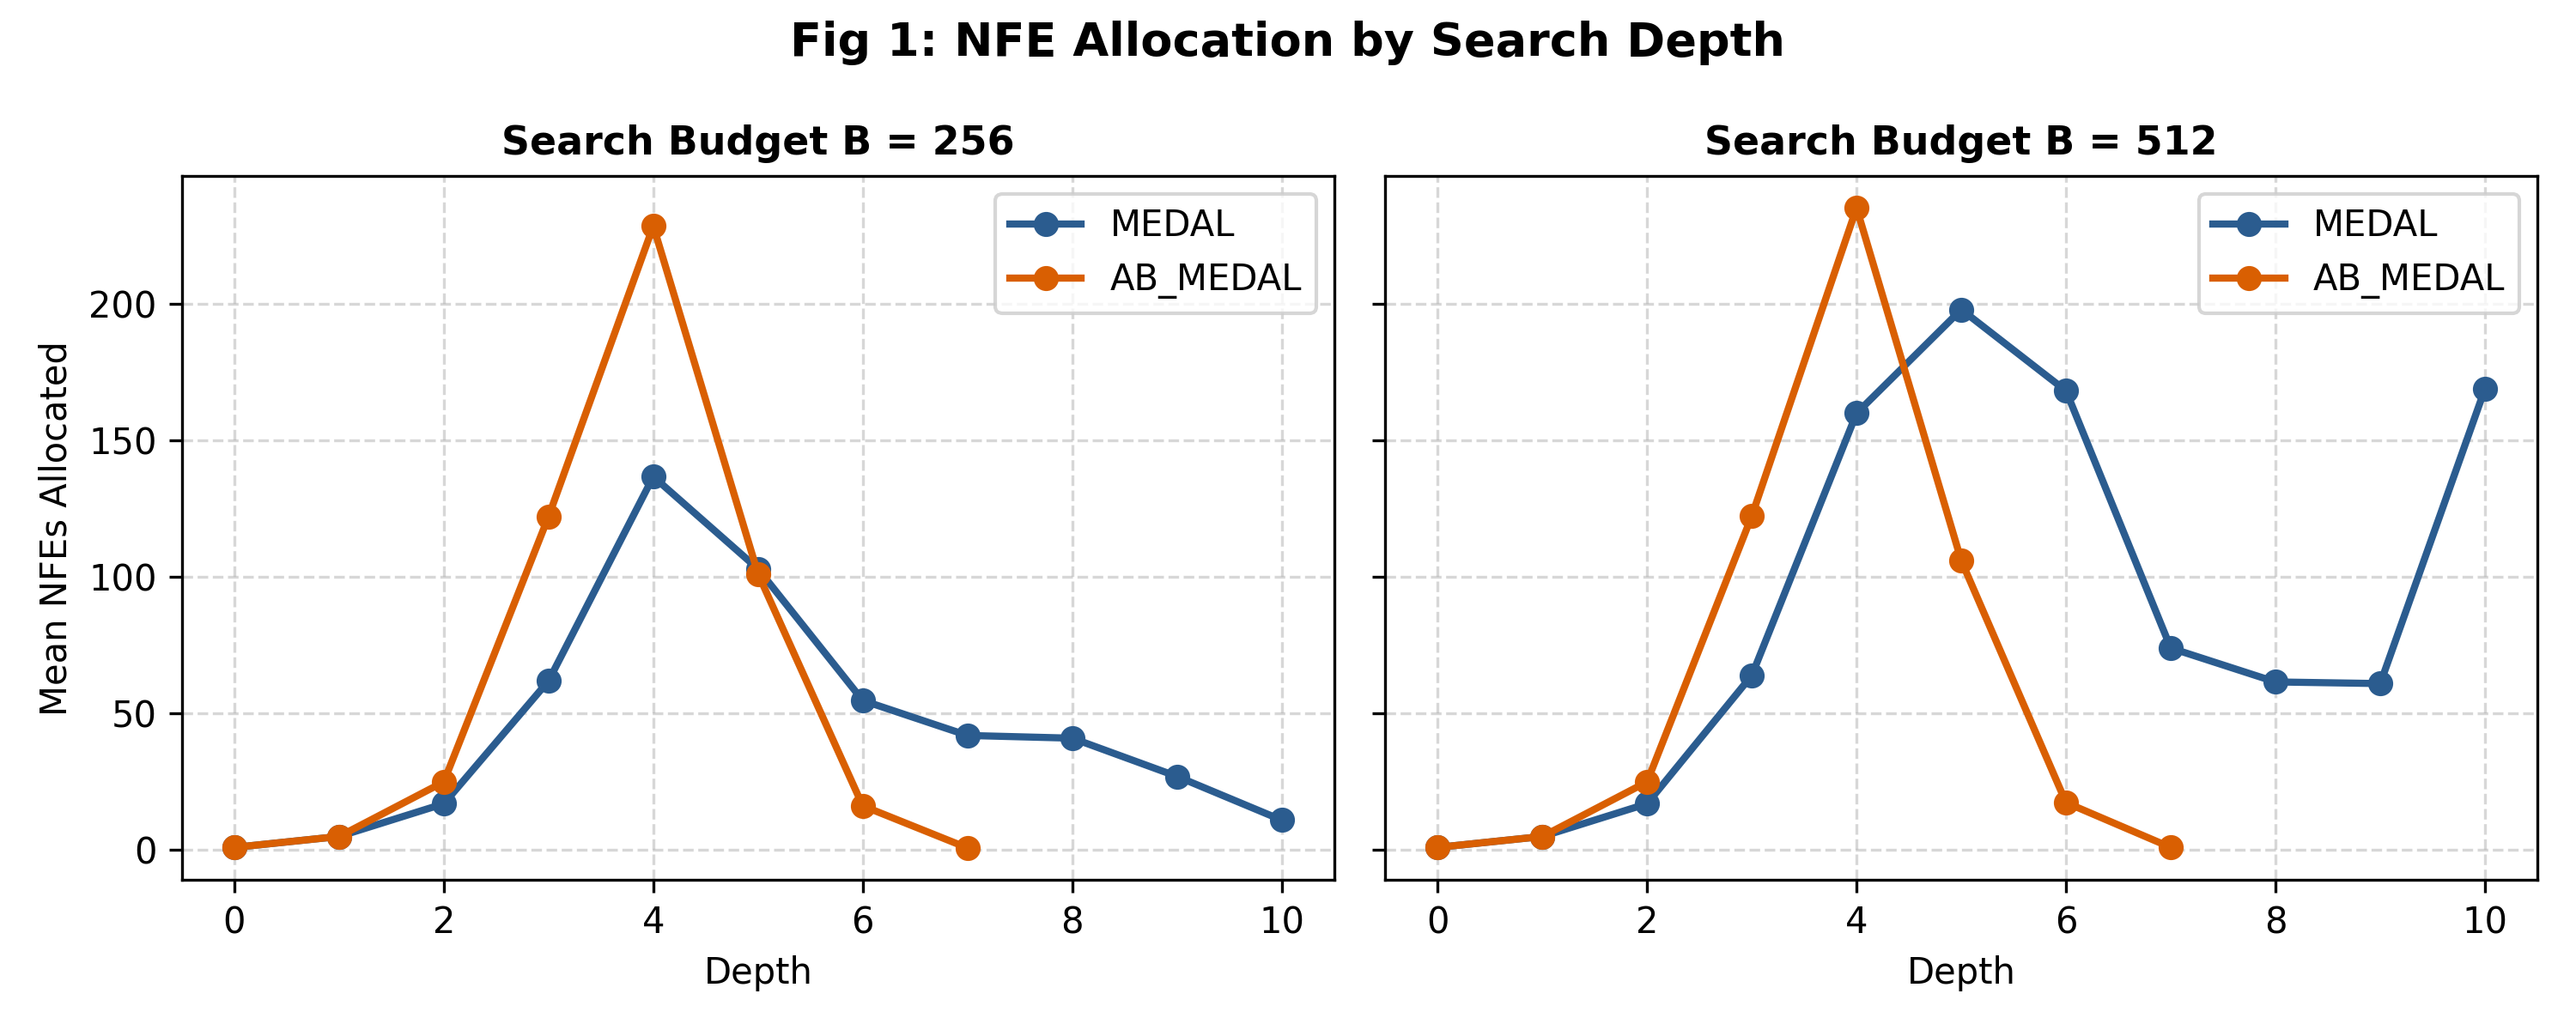

### Figure 2: Branching Factor Distribution — Children per expanded parent

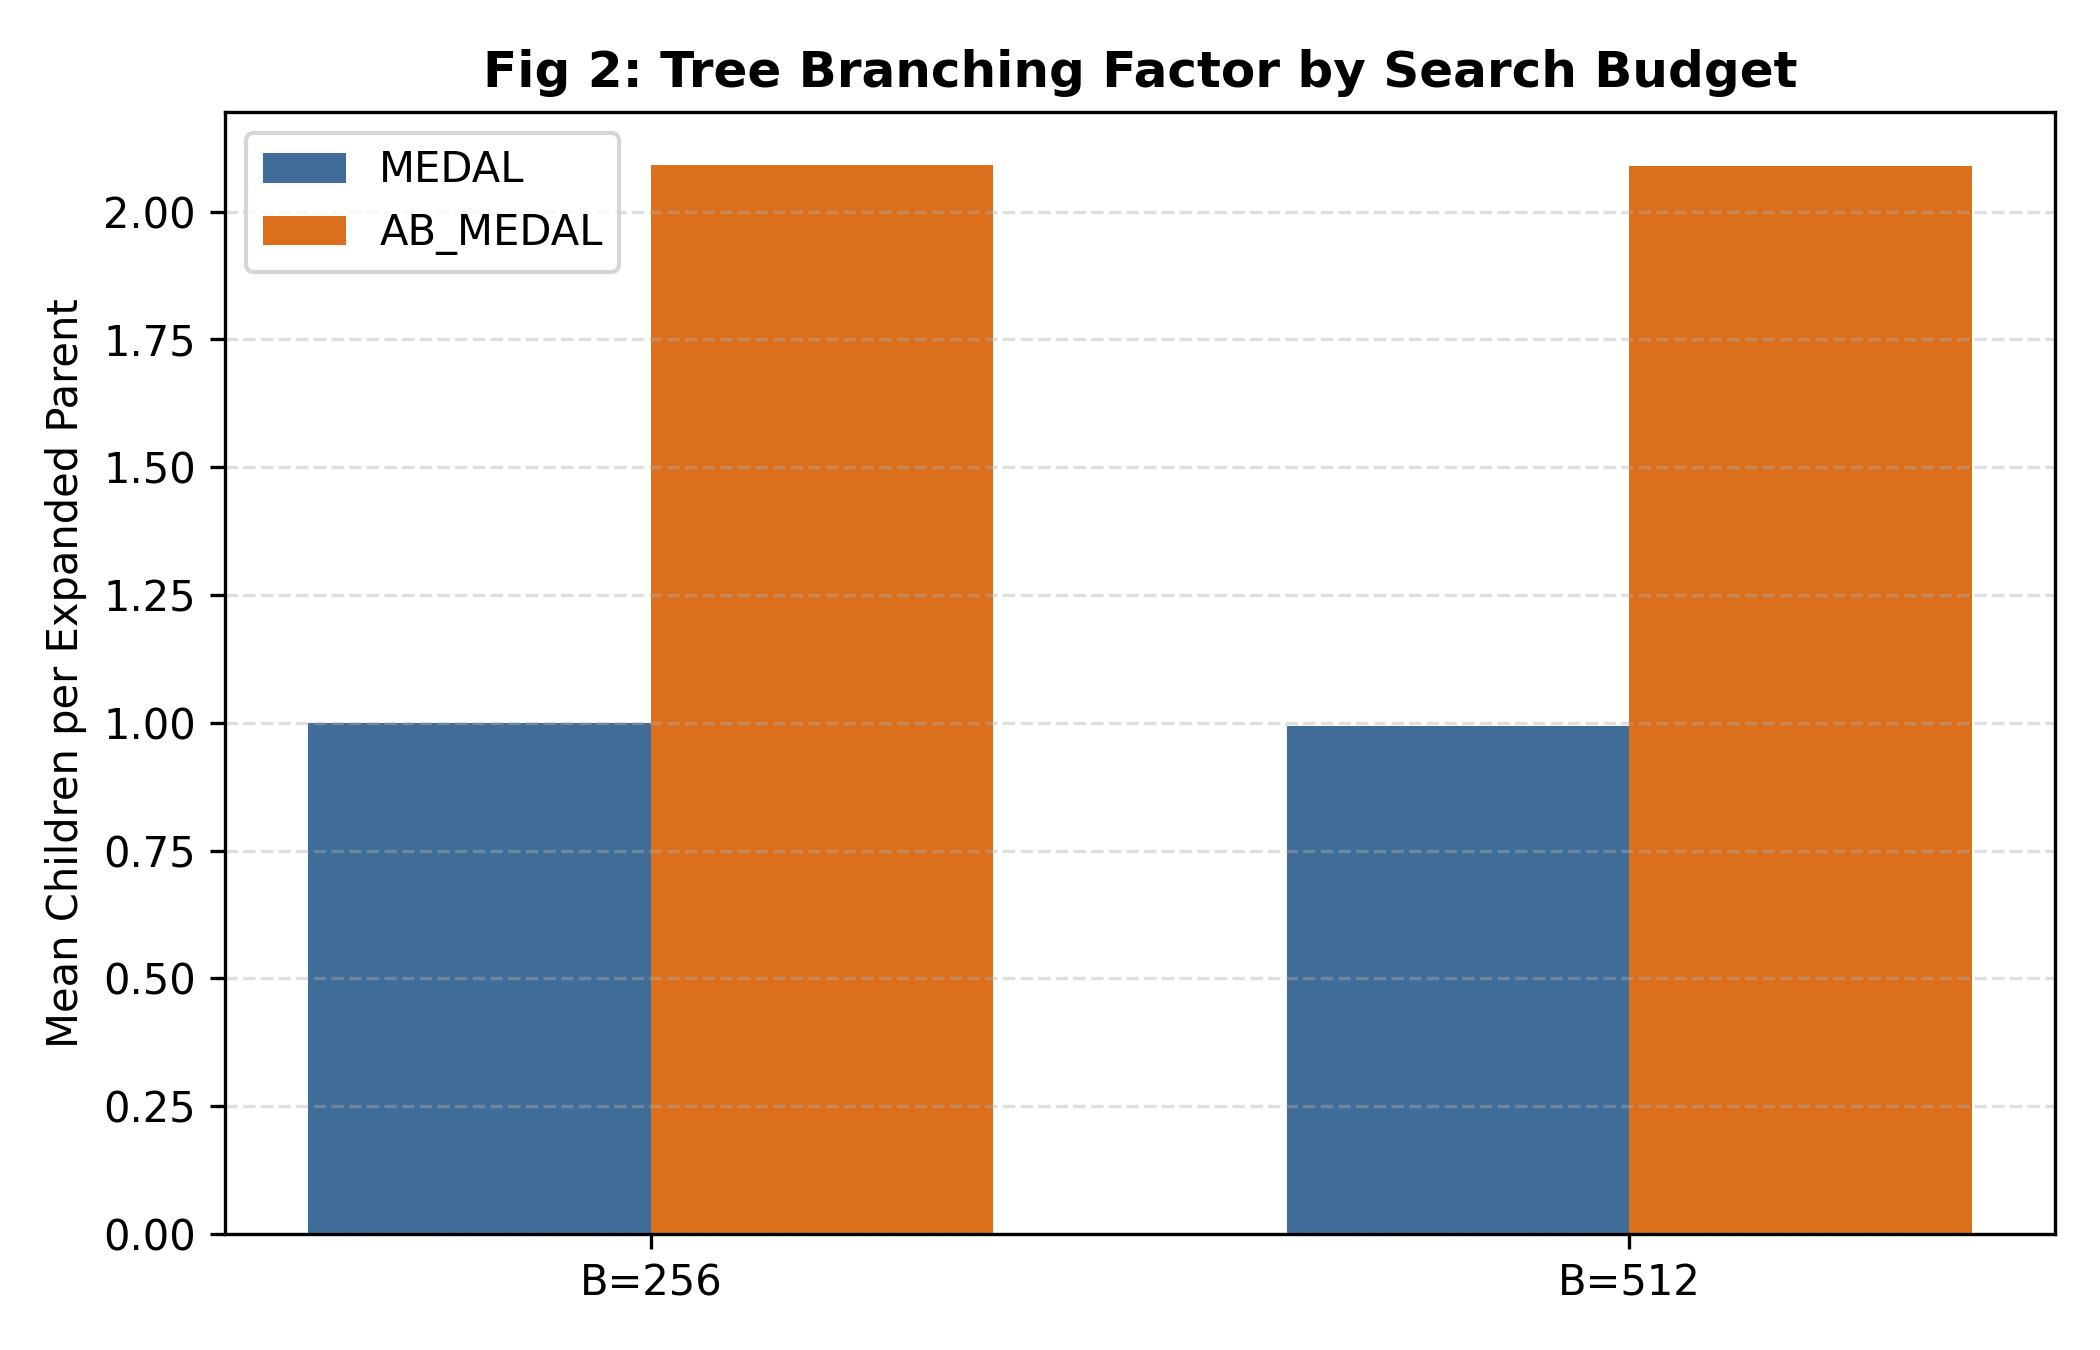

### Figure 3: Candidate Density vs Depth — Minimum-C availability and selection depth

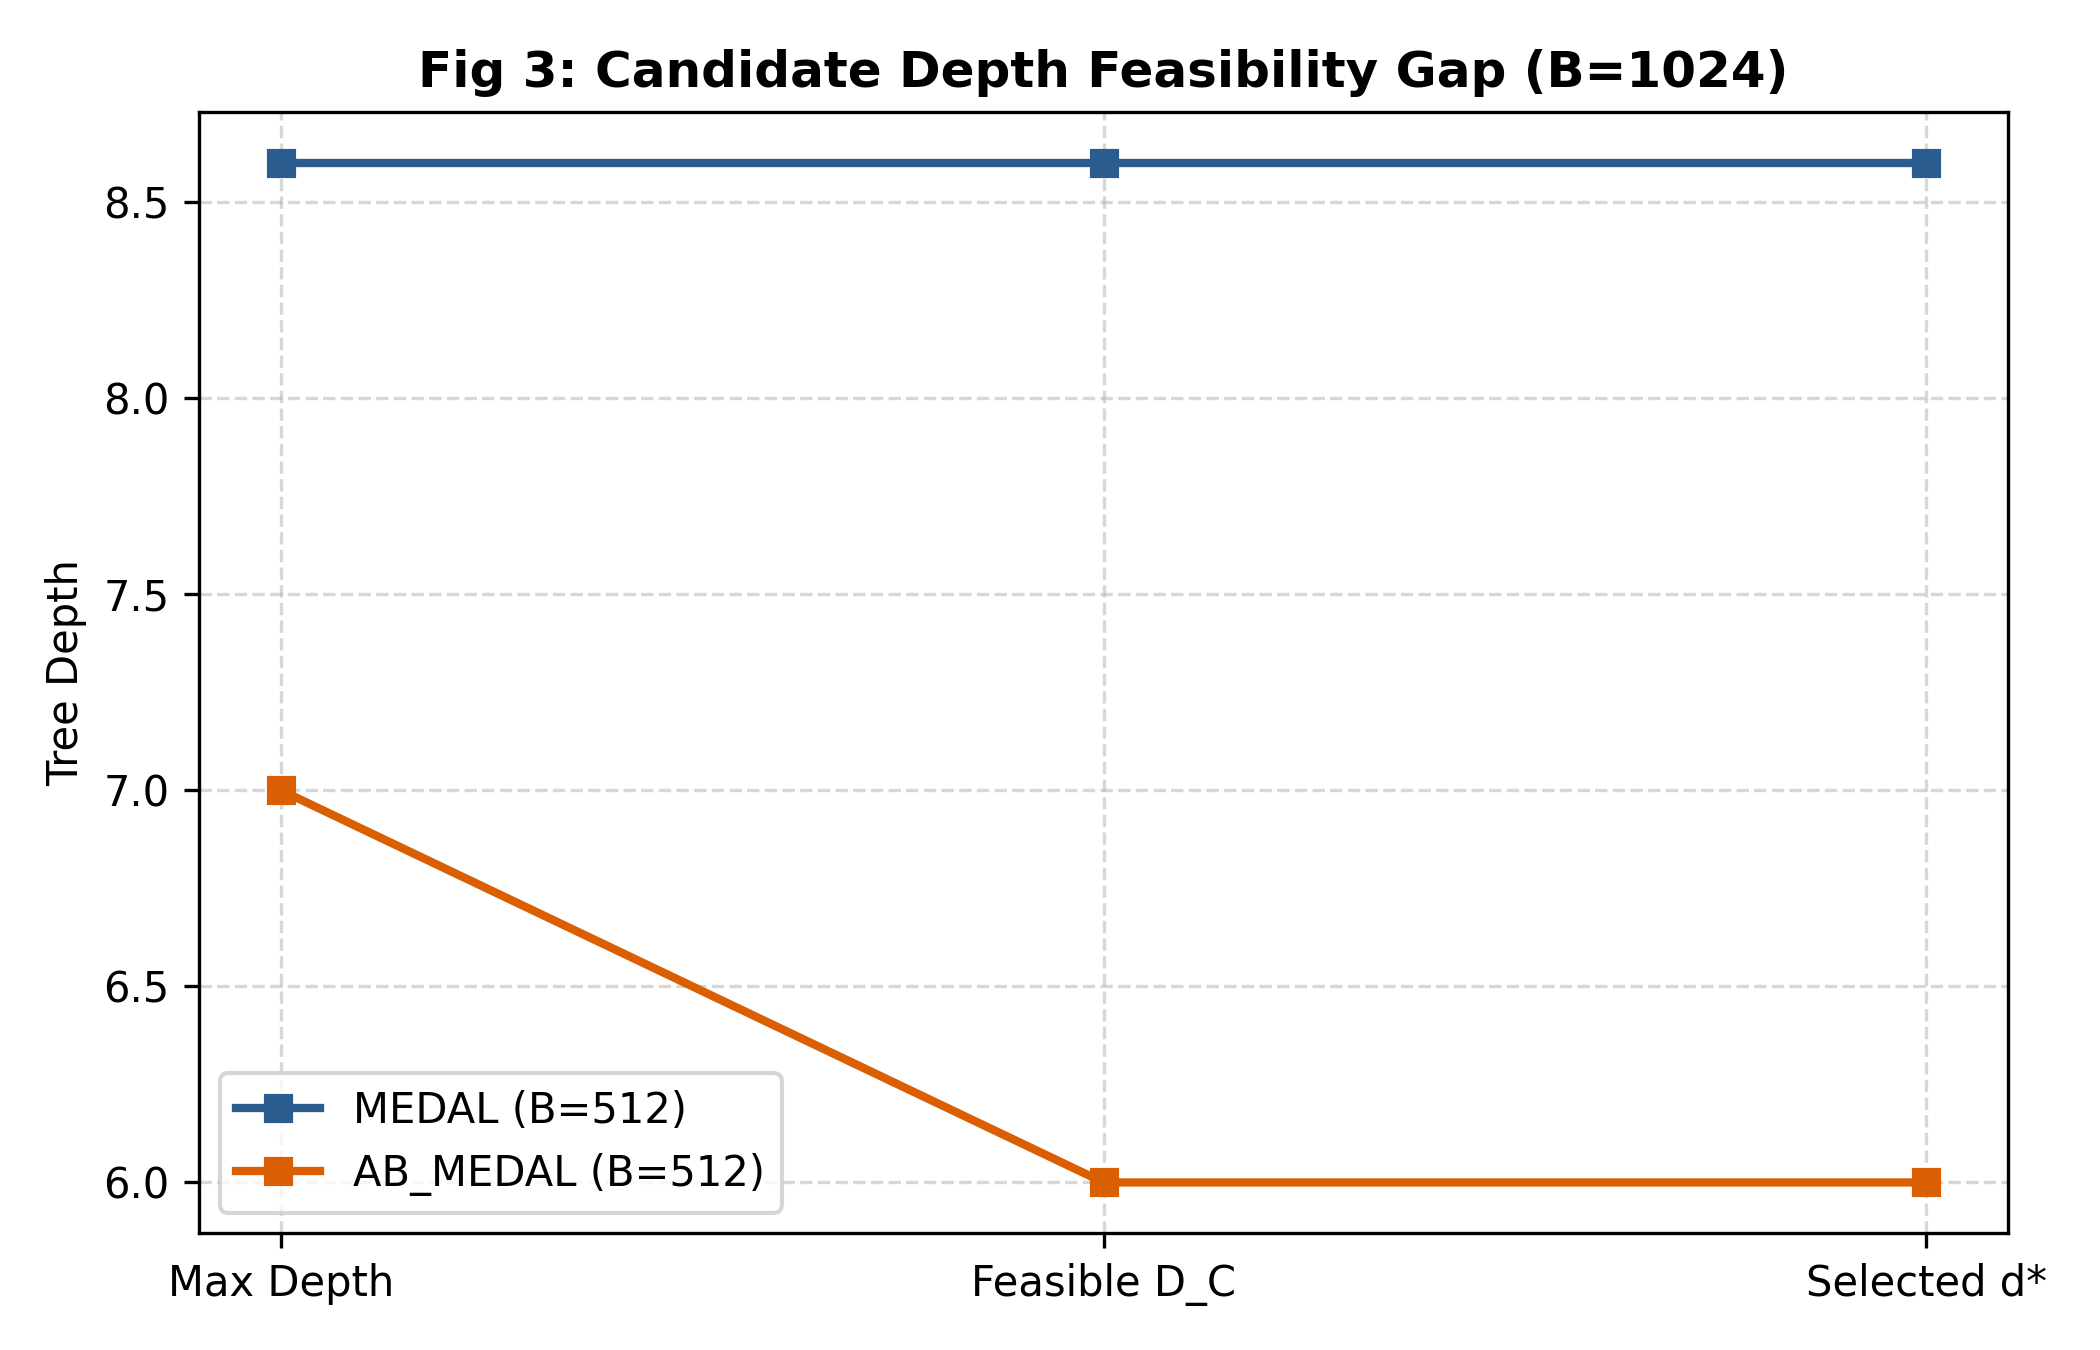

### Figure 4: Root-Subtree Compute Concentration — Search effort across root branches

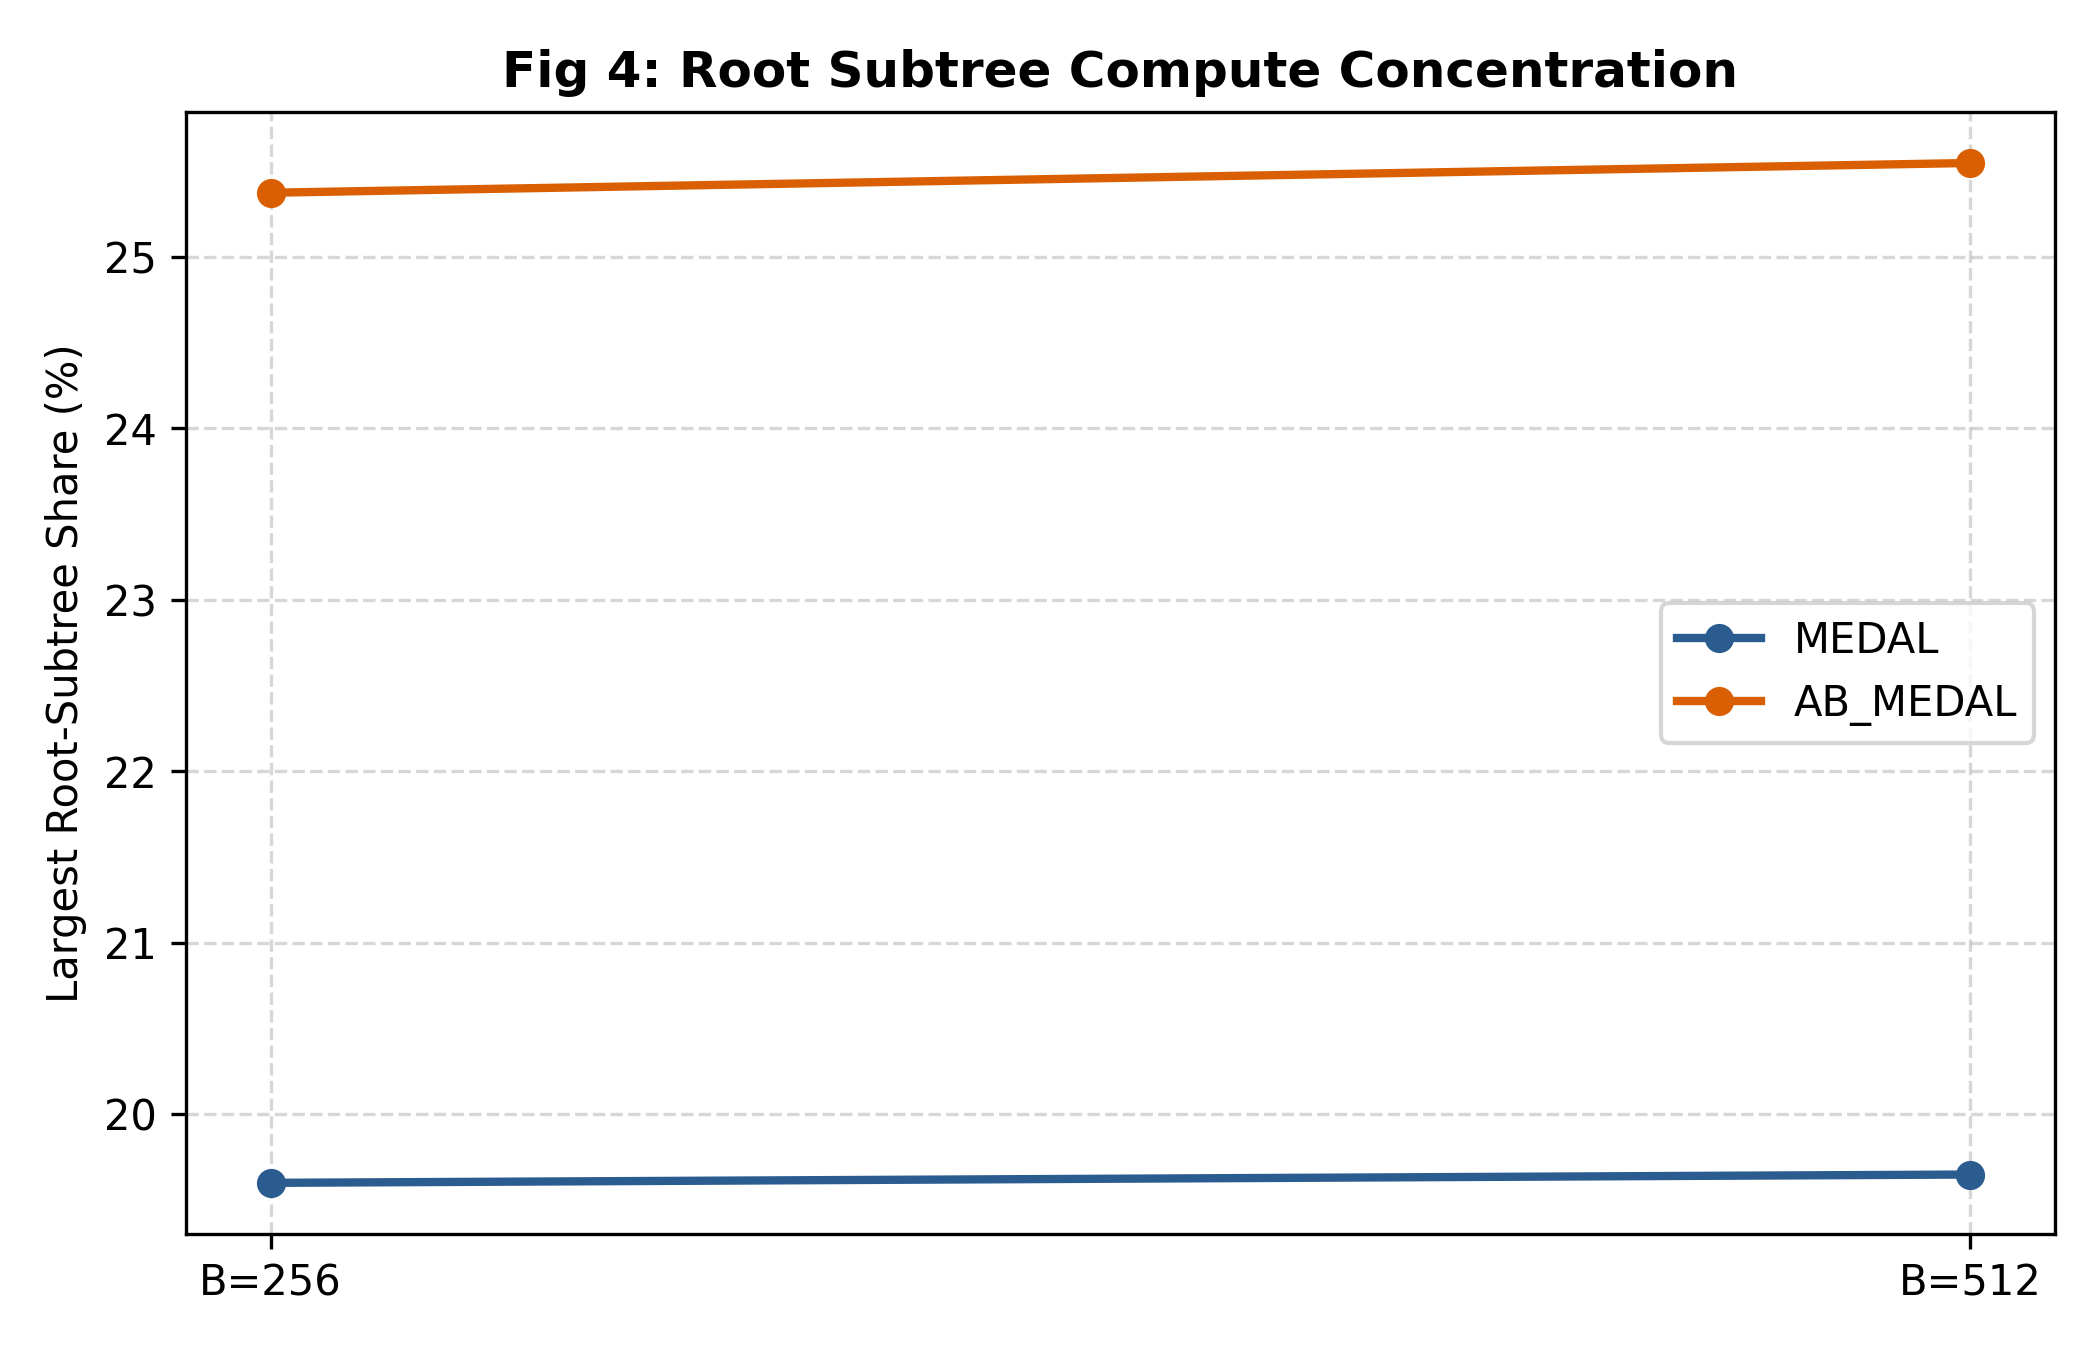

### Figure 5: Reward and Search Redundancy — Negative IG rates and duplicate states

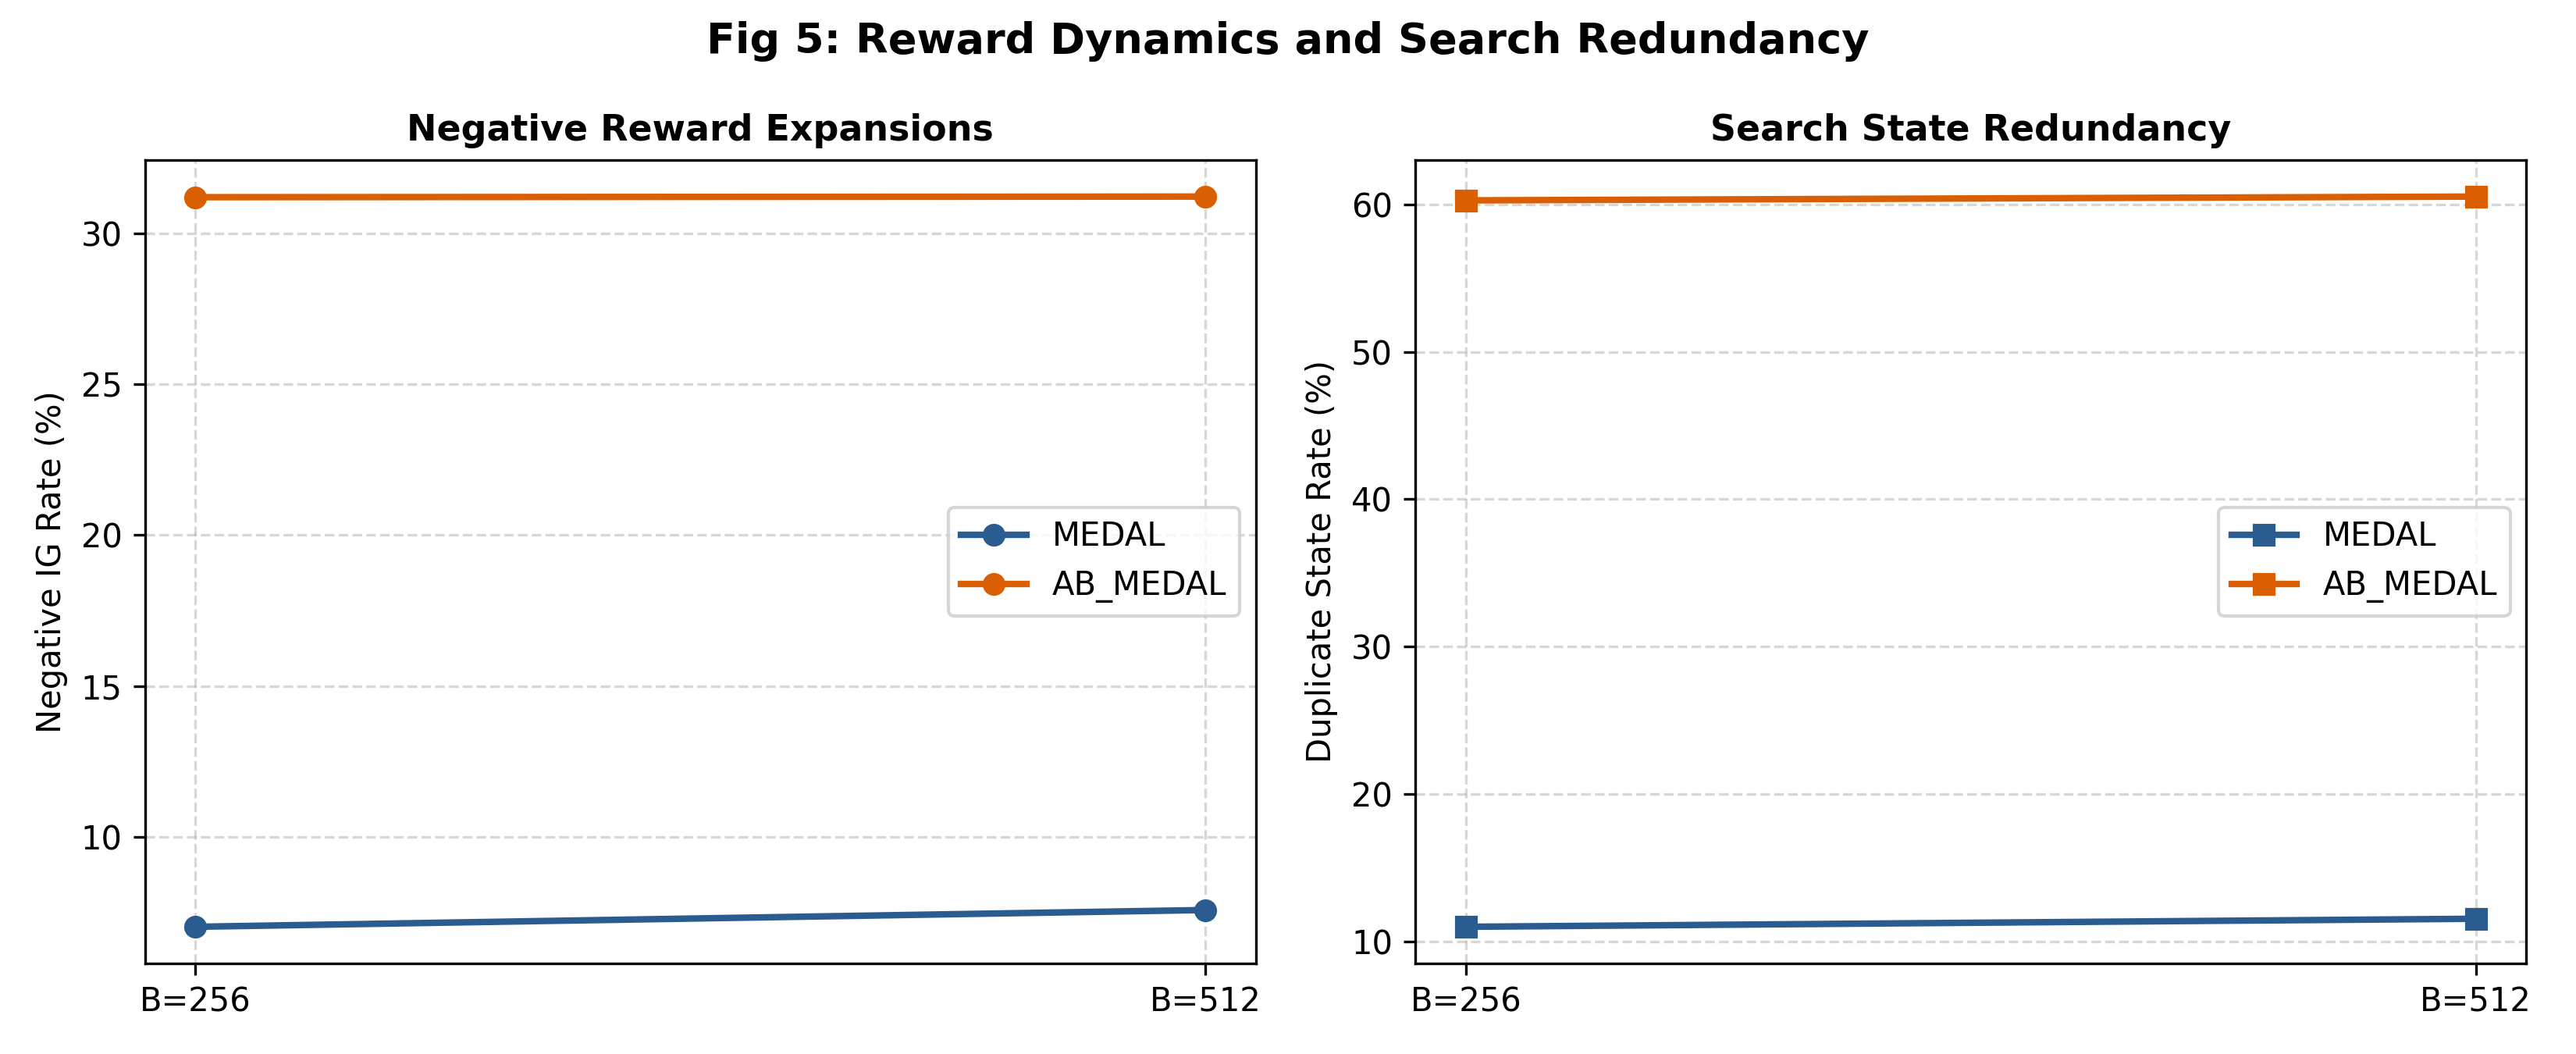

### Figure 6: Accuracy vs Search Budget — Performance scaling curve

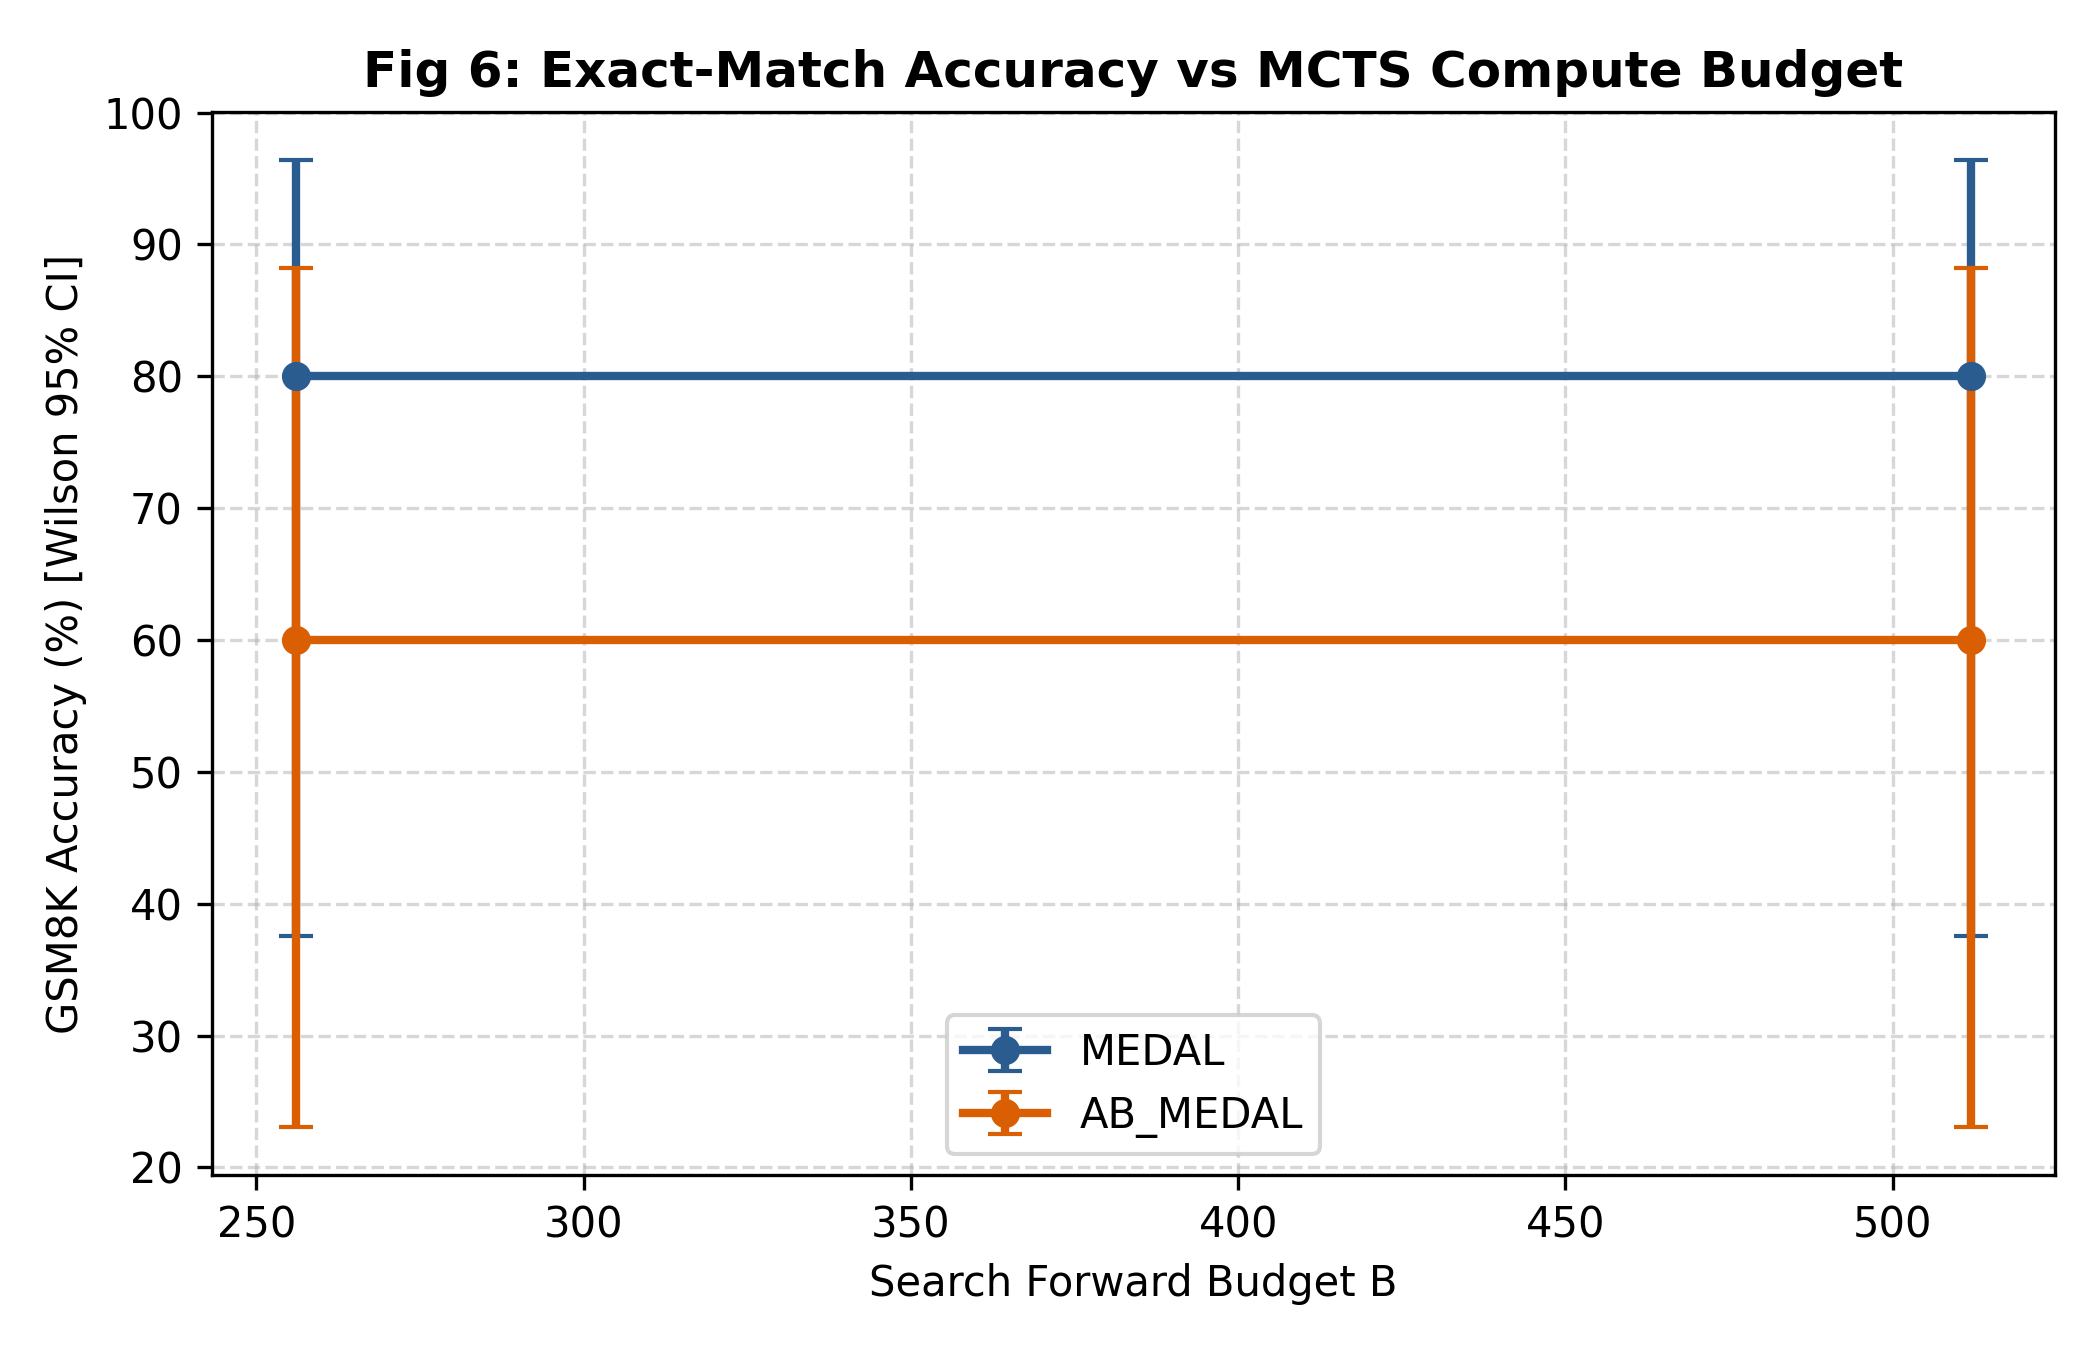

In [11]:
from dlm_project.tasks.gsm8k.e3_analysis import analyze_e3_stage
from IPython.display import Image, display, Markdown

print('Running E3 Offline Tree Allocation & Topology Analysis on E2 traces...')
e3_q, e3_agg = analyze_e3_stage(
    results_dir=OUTPUT_DIR / STAGE,
    output_dir=OUTPUT_DIR / 'summaries',
    stage=STAGE,
    methods=tuple(METHODS),
    budgets=tuple(BUDGETS),
)
print(f'✓ E3 Analysis Completed successfully: {len(e3_q)} question outcomes evaluated.')

figures_dir = OUTPUT_DIR / 'summaries' / 'e3_figures'
fig_titles = {
    'fig1_nfe_by_depth': 'Figure 1: NFE Allocation by Tree Depth — MEDAL vs AB-MEDAL across budgets',
    'fig2_branching_factors': 'Figure 2: Branching Factor Distribution — Children per expanded parent',
    'fig3_candidate_density': 'Figure 3: Candidate Density vs Depth — Minimum-C availability and selection depth',
    'fig4_root_subtrees': 'Figure 4: Root-Subtree Compute Concentration — Search effort across root branches',
    'fig5_reward_redundancy': 'Figure 5: Reward and Search Redundancy — Negative IG rates and duplicate states',
    'fig6_accuracy_vs_budget': 'Figure 6: Accuracy vs Search Budget — Performance scaling curve',
}

for fig_key, title in fig_titles.items():
    png_path = figures_dir / f'{fig_key}.png'
    if png_path.is_file():
        display(Markdown(f'### {title}'))
        display(Image(filename=str(png_path), width=750))


## 12. Synchronize All Artifacts to Google Drive
Explicitly flush and sync all in-flight buffers to Google Drive.

In [12]:
if IN_COLAB:
    from google.colab import drive
    drive.flush_and_unmount()
    print('Google Drive flushed successfully.')


Google Drive flushed successfully.
